## Expensive coffee, richer farmers?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("data/coffee_market.csv")

In [2]:
df.head()

,period_id,period_index,price_usd_kg,quantity_kt,growing_conditions,buyer_activity
0,M001,1,10.837531,133.302350,1.5,2.391855
1,M002,2,8.915661,67.150820,-1.5,-2.516137
2,M003,3,11.694981,88.019068,-1.5,-0.195789
3,M004,4,10.394216,101.971595,0.0,0.117742
4,M005,5,7.323098,95.714836,1.5,-1.148320


### 1 Understand and explore the market

In [3]:
print(df.shape) 
print(df.describe())

(300, 6)
       period_index  price_usd_kg  quantity_kt  growing_conditions  \
count    300.000000    300.000000   300.000000          300.000000   
mean     150.500000     10.007071   100.014193            0.000000   
std       86.746758      2.216562    18.463413            1.226791   
min        1.000000      5.167537    64.153291           -1.500000   
25%       75.750000      8.498644    85.272858           -1.500000   
50%      150.500000     10.031043   100.404945            0.000000   
75%      225.250000     11.474298   115.422765            1.500000   
max      300.000000     14.994600   138.601371            1.500000   

       buyer_activity  
count      300.000000  
mean        -0.005815  
std          1.708899  
min         -2.970926  
25%         -1.524112  
50%         -0.104044  
75%          1.530218  
max          2.877227  


In [4]:
df.isna().sum()

period_id             0
period_index          0
price_usd_kg          0
quantity_kt           0
growing_conditions    0
buyer_activity        0
dtype: int64

In [5]:
print(df.duplicated("period_id").sum())

0


In [6]:
print(df['growing_conditions'].value_counts())

growing_conditions
 1.5    100
-1.5    100
 0.0    100
Name: count, dtype: int64


In [7]:
print((df["price_usd_kg"] <= 0).sum())

0


In [8]:
print((df["quantity_kt"] <= 0).sum())

0


### Finding ###
- There are 300 selling periods and 6 variables, no missing values, no duplicate IDs.
- Units: price is in USD/kg and quantity in thousand tonnes (kt). Since 1 kt = 1 million kg, price × quantity gives sales revenue in million USD.
- Price runs from about 5.2 to 15.0 USD/kg (mean 10.0), quantity from about 64 to 139 kt (mean 100). All values are positive.
- Growing conditions take only three values (−1.5, 0, 1.5) with exactly 100 periods each, so it looks like a designed setup. Buyer activity is continuous and centred near 0.
- period_index only records display order, not time, so the data contain no time trend and we do not analyse it over time.

In [9]:
df = df.assign(revenue_musd=df["price_usd_kg"] * df["quantity_kt"])
df["revenue_musd"].describe()

count     300.000000
mean     1022.828494
std       357.982164
min       382.916016
25%       718.703345
50%       969.607171
75%      1300.917881
max      1858.192295
Name: revenue_musd, dtype: float64

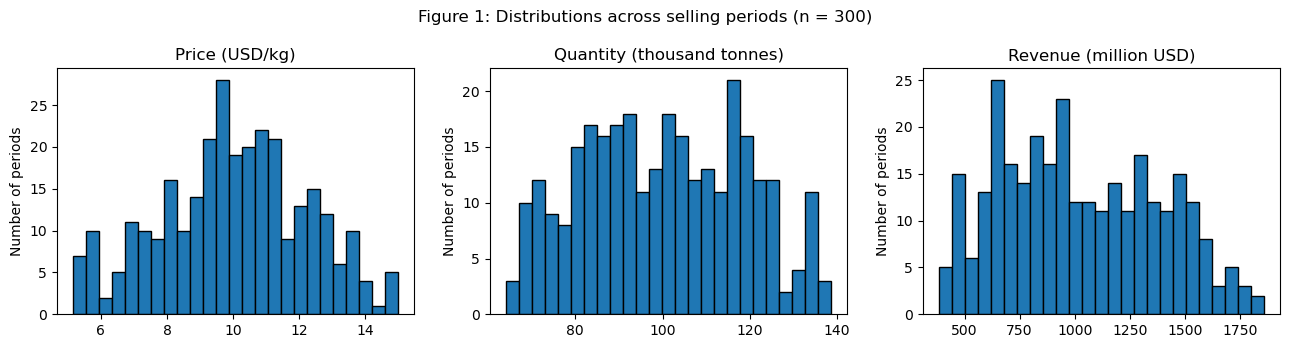

In [10]:
# Distributions of price, quantity and revenue across the 300 selling periods
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].hist(df["price_usd_kg"], bins=25, edgecolor="black")
axes[0].set_title("Price (USD/kg)")

axes[1].hist(df["quantity_kt"], bins=25, edgecolor="black")
axes[1].set_title("Quantity (thousand tonnes)")

axes[2].hist(df["revenue_musd"], bins=25, edgecolor="black")
axes[2].set_title("Revenue (million USD)")

for ax in axes:
    ax.set_ylabel("Number of periods")

fig.suptitle("Figure 1: Distributions across selling periods (n = 300)")
plt.tight_layout()
plt.show()


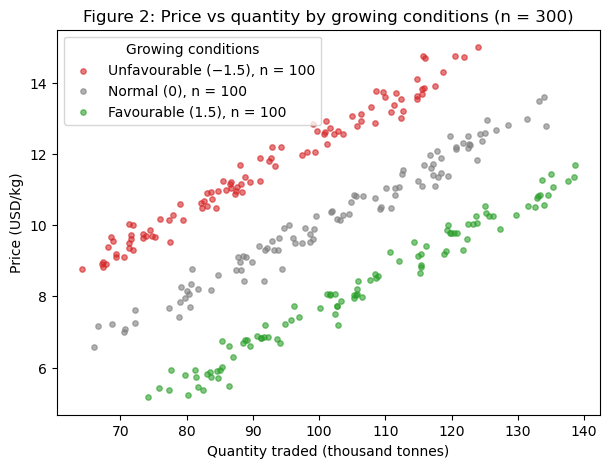

In [11]:
# Price vs quantity, one colour per growing-conditions group
colors = {-1.5: "tab:red", 0.0: "tab:gray", 1.5: "tab:green"}
labels = {-1.5: "Unfavourable (−1.5)", 0.0: "Normal (0)", 1.5: "Favourable (1.5)"}

fig, ax = plt.subplots(figsize=(7, 5))
for value in [-1.5, 0.0, 1.5]:
    group = df[df["growing_conditions"] == value]
    ax.scatter(group["quantity_kt"], group["price_usd_kg"],
               s=15, alpha=0.6, color=colors[value],
               label=f"{labels[value]}, n = {len(group)}")

ax.set_xlabel("Quantity traded (thousand tonnes)")
ax.set_ylabel("Price (USD/kg)")
ax.set_title("Figure 2: Price vs quantity by growing conditions (n = 300)")
ax.legend(title="Growing conditions")
plt.show()

In [12]:
print(df[["price_usd_kg", "quantity_kt"]].corr())
print("Table 1: Average price (USD/kg), quantity (kt) and revenue (million USD) by growing conditions (n = 100 each)")
print(df.groupby("growing_conditions")[["price_usd_kg", "quantity_kt", "revenue_musd"]].mean().round(1))

              price_usd_kg  quantity_kt
price_usd_kg      1.000000     0.538858
quantity_kt       0.538858     1.000000
Table 1: Average price (USD/kg), quantity (kt) and revenue (million USD) by growing conditions (n = 100 each)
                    price_usd_kg  quantity_kt  revenue_musd
growing_conditions                                         
-1.5                        11.6         91.7        1088.9
 0.0                        10.2        102.0        1070.4
 1.5                         8.2        106.3         909.2


### Finding (Q1)
- Overall, P and Q go up together (correlation 0.54).
- By weather (Table 1):
  - Bad harvest: P 11.6 USD/kg, Q 91.7 kt, revenue 1,089 million USD.
  - Good harvest: P 8.2 USD/kg, Q 106.3 kt, revenue 909 million USD.
- Inside each colour the points still slope up.
- Each point is an equilibrium, where S meets D. Both curves move.
- So the upward slope is **not** demand, and it can't tell us how buyers react to a price rise.
- Why each output:
  - The audit shows the data are clean.
  - Figure 1 shows levels and spread.
  - Figure 2 (colours) shows the hidden pattern.
  - Table 1 gives the group numbers.
- Questions raised:
  - What shifts S and what shifts D?
  - Can weather help us find demand?
  - Why do bad harvests earn more?

### 2 Develop an equilibrium explanation
- Each point is where that period's S and D cross. We only see the crossings, not the curves.

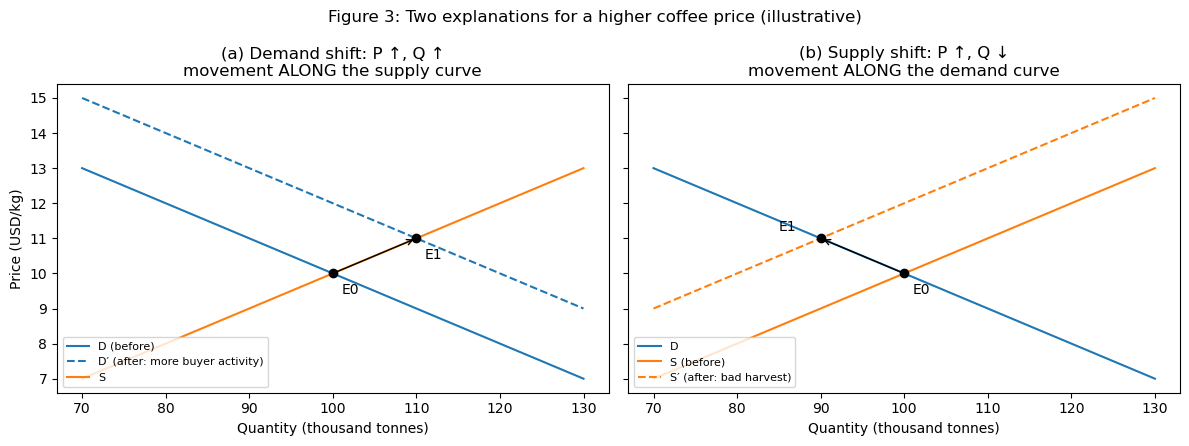

In [13]:
# Illustrative straight lines (not estimates) to show the two explanations
q = np.linspace(70, 130, 100)            # quantity axis (thousand tonnes)

def demand(q, shift=0):
    return 20 - 0.1 * q + shift          # downward-sloping demand

def supply(q, shift=0):
    return 0.1 * q + shift               # upward-sloping supply

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# (a) Demand shifts right: buyers more active
ax = axes[0]
ax.plot(q, demand(q), color="tab:blue", label="D (before)")
ax.plot(q, demand(q, 2), color="tab:blue", ls="--", label="D′ (after: more buyer activity)")
ax.plot(q, supply(q), color="tab:orange", label="S")
ax.annotate("", xy=(110, 11), xytext=(100, 10), arrowprops=dict(arrowstyle="->"))
ax.plot([100, 110], [10, 11], "ko")
ax.text(101, 9.4, "E0"); ax.text(111, 10.4, "E1")
ax.set_title("(a) Demand shift: P ↑, Q ↑\nmovement ALONG the supply curve")

# (b) Supply shifts left: bad harvest
ax = axes[1]
ax.plot(q, demand(q), color="tab:blue", label="D")
ax.plot(q, supply(q), color="tab:orange", label="S (before)")
ax.plot(q, supply(q, 2), color="tab:orange", ls="--", label="S′ (after: bad harvest)")
ax.annotate("", xy=(90, 11), xytext=(100, 10), arrowprops=dict(arrowstyle="->"))
ax.plot([100, 90], [10, 11], "ko")
ax.text(101, 9.4, "E0"); ax.text(85, 11.2, "E1")
ax.set_title("(b) Supply shift: P ↑, Q ↓\nmovement ALONG the demand curve")

for ax in axes:
    ax.set_xlabel("Quantity (thousand tonnes)")
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("Price (USD/kg)")
fig.suptitle("Figure 3: Two explanations for a higher coffee price (illustrative)")
plt.tight_layout()
plt.show()

**Figure 3**
- (a) D shifts right: P up, Q up. The market moves along S.
- (b) S shifts left: P up, Q down. The market moves along D.
- The same price rise can have two causes, and Q tells you which one.
- **Shift:** caused by something that isn't the price (weather, buyers). **Movement along:** the price changed because the other curve moved.
- Link to the data:
  - Between weather groups, the points move along D.
  - Within a group, buyer activity moves D, so the points trace S. That's why the cloud slopes up.

**Proposed comparison**
- Compare good-harvest vs bad-harvest periods.
- What changes: growing conditions, which shift supply only.
- What must stay the same: demand (buyer activity and the rest).
- Why it works: if only supply moves, both group averages are on the same demand curve, so the line between them is demand.
- The normal group should sit roughly on that line (a check).
- Assumptions: weather has nothing to do with buyers; buyer activity doesn't change costs; price-taking, market clearing, same quality, no storage.

In [14]:
print("Table 2: Buyer activity by growing conditions")
print(df.groupby("growing_conditions")["buyer_activity"].agg(["mean", "std", "count"]).round(2))

Table 2: Buyer activity by growing conditions
                    mean   std  count
growing_conditions                   
-1.5               -0.07  1.69    100
 0.0                0.20  1.67    100
 1.5               -0.15  1.76    100


**Balance check (Table 2)**
- Buyer activity means: −0.07, 0.20, −0.15, with a spread of about 1.7.
- Similar across groups, so demand is comparable.

**Unobserved shocks**
- Fine if they're unrelated to weather: they average out, adding noise but no bias.
- 100 periods per group keeps the noise small.
- It would break if weather affected buyers.
- This can't be checked, only assumed.

### 3 Measure the demand response

In [15]:
means = df.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].agg(["mean", "sem"])
print("Table 3: Mean and standard error of price (USD/kg) and quantity (kt), n = 100 per group")
print(means.round(2))

m = df.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].mean()
dP = m.loc[1.5, "price_usd_kg"] - m.loc[-1.5, "price_usd_kg"]
dQ = m.loc[1.5, "quantity_kt"] - m.loc[-1.5, "quantity_kt"]
raw_slope = dQ / dP
P_mid_raw = (m.loc[1.5, "price_usd_kg"] + m.loc[-1.5, "price_usd_kg"]) / 2
Q_mid_raw = (m.loc[1.5, "quantity_kt"] + m.loc[-1.5, "quantity_kt"]) / 2
raw_elast = raw_slope * P_mid_raw / Q_mid_raw

print(f"\nFavourable vs unfavourable: ΔP = {dP:.2f} USD/kg, ΔQ = {dQ:.2f} kt")
print(f"Demand slope: {raw_slope:.2f} kt per USD/kg; elasticity at midpoint "
      f"(P = {P_mid_raw:.2f}, Q = {Q_mid_raw:.1f}): {raw_elast:.2f}")


Table 3: Mean and standard error of price (USD/kg) and quantity (kt), n = 100 per group
                   price_usd_kg       quantity_kt      
                           mean   sem        mean   sem
growing_conditions                                     
-1.5                      11.57  0.17       91.69  1.66
 0.0                      10.20  0.17      102.04  1.76
 1.5                       8.25  0.18      106.31  1.81

Favourable vs unfavourable: ΔP = -3.32 USD/kg, ΔQ = 14.63 kt
Demand slope: -4.40 kt per USD/kg; elasticity at midpoint (P = 9.91, Q = 99.0): -0.44


In [16]:
pooled_slope, pooled_int = np.polyfit(df["price_usd_kg"], df["quantity_kt"], 1)
pooled_elast = pooled_slope * df["price_usd_kg"].mean() / df["quantity_kt"].mean()
print(f"Pooled line (all 300 points): slope {pooled_slope:.2f} kt per USD/kg, elasticity {pooled_elast:.2f}")

Pooled line (all 300 points): slope 4.49 kt per USD/kg, elasticity 0.45


In [17]:
import statsmodels.formula.api as smf

model_q = smf.ols("quantity_kt ~ C(growing_conditions) + buyer_activity", data=df).fit()
model_p = smf.ols("price_usd_kg ~ C(growing_conditions) + buyer_activity", data=df).fit()
grid = pd.DataFrame({"growing_conditions": [-1.5, 0.0, 1.5], "buyer_activity": [0, 0, 0]})
grid = grid.assign(Q_adj=model_q.predict(grid), P_adj=model_p.predict(grid))
print("Table 4: Group means at buyer_activity = 0")
print(grid.round(2))

lo, hi = grid.iloc[0], grid.iloc[2]
slope = (hi["Q_adj"] - lo["Q_adj"]) / (hi["P_adj"] - lo["P_adj"])
P_mid, Q_mid = (lo["P_adj"] + hi["P_adj"]) / 2, (lo["Q_adj"] + hi["Q_adj"]) / 2
elast = slope * P_mid / Q_mid
print(f"\nAdjusted slope: {slope:.2f} kt per USD/kg; elasticity at P = {P_mid:.2f}, Q = {Q_mid:.1f}: {elast:.2f}")

Q_line = Q_mid + slope * (grid.loc[1, "P_adj"] - P_mid)
print(f"Normal group: actual Q = {grid.loc[1, 'Q_adj']:.1f}, line predicts {Q_line:.1f}")


Table 4: Group means at buyer_activity = 0
   growing_conditions  buyer_activity   Q_adj  P_adj
0                -1.5               0   92.37  11.64
1                 0.0               0  100.01  10.00
2                 1.5               0  107.84   8.40

Adjusted slope: -4.78 kt per USD/kg; elasticity at P = 10.02, Q = 100.1: -0.48
Normal group: actual Q = 100.0, line predicts 100.2


In [18]:
def group_slope(d):
    g = d.groupby("growing_conditions")[["price_usd_kg", "quantity_kt"]].mean()
    return ((g.loc[1.5, "quantity_kt"] - g.loc[-1.5, "quantity_kt"]) /
            (g.loc[1.5, "price_usd_kg"] - g.loc[-1.5, "price_usd_kg"]))

# (a) Does the slope change with buyer conditions?
print(f"Slope, low buyer activity (< 0):   {group_slope(df[df['buyer_activity'] < 0]):.2f}")
print(f"Slope, high buyer activity (>= 0): {group_slope(df[df['buyer_activity'] >= 0]):.2f}")

# (b) Resampling: redraw each group's 100 periods with replacement, 1000 times
rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    idx = np.concatenate([rng.choice(g.index, size=len(g), replace=True)
                          for _, g in df.groupby("growing_conditions")])
    boot.append(group_slope(df.loc[idx]))
boot = np.array(boot)
lo95, hi95 = np.percentile(boot, [2.5, 97.5])
print(f"\nResampled slope, middle 95%: {lo95:.2f} to {hi95:.2f} kt per USD/kg")
print(f"Implied elasticity range: {lo95 * P_mid_raw / Q_mid_raw:.2f} to {hi95 * P_mid_raw / Q_mid_raw:.2f}")

Slope, low buyer activity (< 0):   -4.05
Slope, high buyer activity (>= 0): -4.84

Resampled slope, middle 95%: -7.16 to -2.56 kt per USD/kg
Implied elasticity range: -0.72 to -0.26


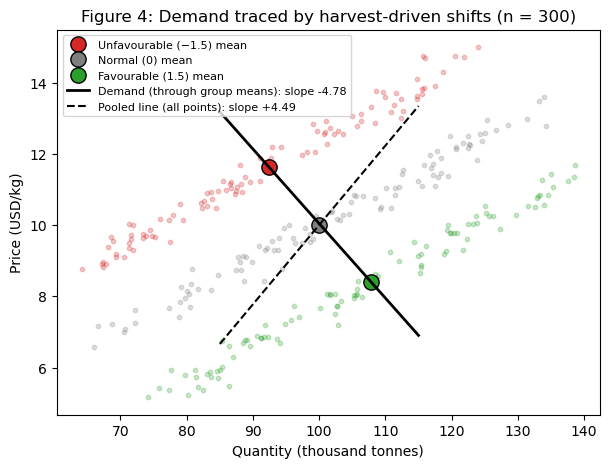

In [19]:
q_line = np.linspace(85, 115, 50)
fig, ax = plt.subplots(figsize=(7, 5))
for value in [-1.5, 0.0, 1.5]:
    g = df[df["growing_conditions"] == value]
    ax.scatter(g["quantity_kt"], g["price_usd_kg"], s=10, alpha=0.25, color=colors[value])
    ax.plot(grid.loc[grid["growing_conditions"] == value, "Q_adj"],
            grid.loc[grid["growing_conditions"] == value, "P_adj"],
            "o", ms=11, mec="black", color=colors[value], label=f"{labels[value]} mean")
ax.plot(q_line, P_mid + (q_line - Q_mid) / slope, "k-", lw=2,
        label=f"Demand (through group means): slope {slope:.2f}")
ax.plot(q_line, (q_line - pooled_int) / pooled_slope, "k--",
        label=f"Pooled line (all points): slope +{pooled_slope:.2f}")
ax.set_xlabel("Quantity (thousand tonnes)")
ax.set_ylabel("Price (USD/kg)")
ax.set_title("Figure 4: Demand traced by harvest-driven shifts (n = 300)")
ax.legend(fontsize=8)
plt.show()


**Finding (Q3)**

**Main result**
- Good vs bad harvest: P down 3.3 USD/kg, Q up 14.6 kt.
- Slope −4.4: 1 USD/kg more means about 4.4 kt less.
- Elasticity −0.44 at P ≈ 10, Q ≈ 100. Inelastic: 1% more price means about 0.44% less bought.
- With buyer activity held at 0: slope −4.8, elasticity −0.48.
- Inelastic demand explains why bad harvests earn more.

**Why a line works**
- Only supply moves, so both group averages are on the same D curve.
- The normal group is almost exactly on the line (100.0 vs 100.2).

**Pooled line**
- +4.5, the wrong sign. It mostly traces supply (Figure 4).

**Buyer conditions**
- Controlling for them: −4.4 becomes −4.8.
- Low vs high activity: −4.1 vs −4.8.
- The conclusion doesn't change.

**Checked vs assumed**
- Checked: balance across groups, normal group on the line, stable slope.
- Assumed: weather has nothing to do with unobserved demand, and there's no storage.
- What would make us doubt it: big imbalance, normal group off the line, very different slopes.

**Uncertainty**
- Resampling: slope −2.6 to −7.2, elasticity −0.26 to −0.72.
- Always negative and inelastic, but the exact size is unsure (only 3 averages).
- Only valid for prices of about 8–12 USD/kg.

### 4 Investigate two price increases

In [20]:
ep = pd.read_csv("data/coffee_episodes.csv")
ep = ep.assign(revenue_musd=ep["price_usd_kg"] * ep["quantity_kt"])

cols = ["price_usd_kg", "quantity_kt", "revenue_musd", "growing_conditions", "buyer_activity"]
ep_means = ep.groupby(["episode", "phase"])[cols].mean()
print("Table 7: Episode averages (n = 10 per cell)")
print(ep_means.round(2))

changes = (ep_means.xs("During", level="phase") - ep_means.xs("Before", level="phase"))
changes = changes.assign(revenue_pct=100 * changes["revenue_musd"]
                         / ep_means.xs("Before", level="phase")["revenue_musd"])
print("\nTable 8: Change, During minus Before")
print(changes.round(2))

Table 7: Episode averages (n = 10 per cell)
                price_usd_kg  quantity_kt  revenue_musd  growing_conditions  \
episode phase                                                                 
A       Before          9.98       100.00        997.94                 0.0   
        During         11.55        91.71       1059.24                -1.5   
B       Before         10.04       100.13       1004.87                 0.0   
        During         11.64       116.39       1354.23                 0.0   

                buyer_activity  
episode phase                   
A       Before             0.0  
        During             0.0  
B       Before             0.0  
        During             1.6  

Table 8: Change, During minus Before
         price_usd_kg  quantity_kt  revenue_musd  growing_conditions  \
episode                                                                
A                1.57        -8.29         61.29                -1.5   
B                1.60        

In [21]:
dP_A = changes.loc["A", "price_usd_kg"]
dQ_A = changes.loc["A", "quantity_kt"]
print(f"Episode A: price +{dP_A:.2f} USD/kg; actual ΔQ = {dQ_A:.2f} kt; "
      f"demand slope predicts ΔQ = {slope * dP_A:.2f} kt")

Episode A: price +1.57 USD/kg; actual ΔQ = -8.29 kt; demand slope predicts ΔQ = -7.50 kt


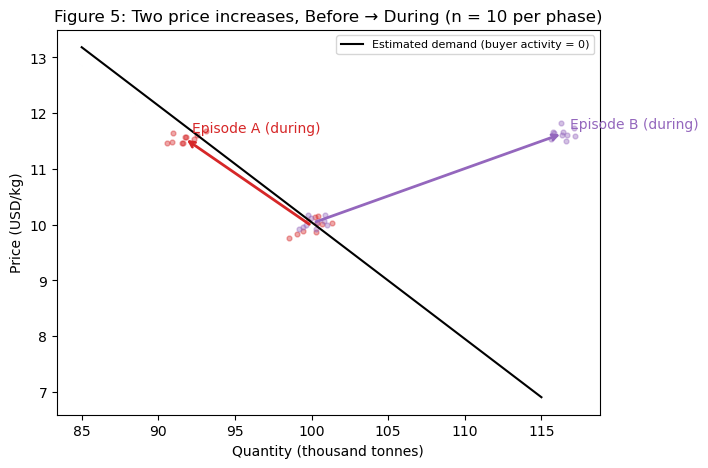

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, color in [("A", "tab:red"), ("B", "tab:purple")]:
    before = ep_means.loc[(name, "Before")]
    during = ep_means.loc[(name, "During")]
    pts = ep[ep["episode"] == name]
    ax.scatter(pts["quantity_kt"], pts["price_usd_kg"], s=12, alpha=0.4, color=color)
    ax.annotate("", xy=(during["quantity_kt"], during["price_usd_kg"]),
                xytext=(before["quantity_kt"], before["price_usd_kg"]),
                arrowprops=dict(arrowstyle="->", color=color, lw=2))
    ax.text(during["quantity_kt"] + 0.5, during["price_usd_kg"] + 0.1, f"Episode {name} (during)", color=color)
ax.plot(q_line, P_mid + (q_line - Q_mid) / slope, "k-", label="Estimated demand (buyer activity = 0)")
ax.set_xlabel("Quantity (thousand tonnes)")
ax.set_ylabel("Price (USD/kg)")
ax.set_title("Figure 5: Two price increases, Before → During (n = 10 per phase)")
ax.legend(fontsize=8)
plt.show()


**Finding (Q4)**
- Both episodes: price goes up about 1.6 USD/kg.
- **A:** weather goes bad (0 → −1.5), buyers unchanged.
  - Supply shifts left, so the market moves along demand.
  - Q down 8.3 kt. Our slope predicted about −7.5, close.
  - Revenue +61 million USD (+6%), but less coffee sold.
- **B:** weather normal, buyer activity up (0 → 1.6).
  - Demand shifts right, so the market moves along supply.
  - Q up 16.3 kt. Revenue +349 million USD (+35%).
  - Our elasticity doesn't apply here, because it's not a move along demand.
- **Lesson:** same price rise, very different result for sellers. The cause matters.
- **We can't say:**
  - Profits went up: no cost data.
  - Every farmer gained: no farm-level data, and in A some farmers lost their crop.
  - Society is better off: in A, buyers pay more for less coffee and less is traded. To be sure we'd need buyer surplus and costs.
- Only 10 periods per phase, but the differences are big.